# PSX Announcements EDA - all companies (2018+)

125k announcements for 667 companies scraped from the PSX data portal (`data/announcements.csv`). Event types tagged with a keyword baseline.

In [1]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

ROOT = Path(r"D:\PSX_Document_Description")

# -- chart style (validated palette; light mode) --
CAT     = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ     = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#1c5cab", "#104281", "#0d366b"]
SURFACE, GRID, BASE = "#fcfcfb", "#e1e0d9", "#c3c2b7"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
BLUE = "#2a78d6"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "axes.edgecolor": BASE, "axes.linewidth": 0.8, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
SEQ_CMAP = mpl.colors.LinearSegmentedColormap.from_list("seq_blue", SEQ)

EVENT_PATTERNS = [
    ("FINANCIAL_RESULT", r"financial result|quarterly report|annual report|half yearly|accounts for"),
    ("BOARD_MEETING", r"board meeting"),
    ("DIVIDEND", r"dividend"),
    ("AGM_EGM", r"annual general meeting|extraordinary general meeting|\bagm\b|\begm\b|general meeting"),
    ("EXEC_CHANGE", r"appointment|resignation|casual vacancy|chief executive|director|company secretary|\bcfo\b|change of management|change of chairman"),
    ("CORP_BRIEFING", r"corporate briefing|analyst briefing"),
    ("MERGER_ACQUISITION", r"merger|amalgamation|acquisition|scheme of arrangement|takeover"),
    ("RIGHTS_ISSUE", r"right issue|rights issue|right shares"),
    ("BUYBACK", r"buy back|buyback|repurchase"),
    ("CREDIT_RATING", r"credit rating|rating report|entity rating"),
    ("DISCLOSURE_INTEREST", r"disclosure of interest|substantial shareholder|free float"),
    ("BOOK_CLOSURE", r"book closure|closed period|register of members"),
    ("MATERIAL_INFO", r"material information|price sensitive"),
    ("TRANSMISSION_REPORT", r"transmission of"),
]
def tag_event(title):
    t = str(title).lower()
    for name, pat in EVENT_PATTERNS:
        if re.search(pat, t):
            return name
    return "OTHER"

## 0. Load data

In [2]:
df = pd.read_csv(ROOT / "data" / "announcements.csv")
df["dt"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["dt"].dt.year
df["event"] = df["title"].map(tag_event)
print(f"rows: {len(df):,} | companies: {df.symbol.nunique()} | span: {df.date.min()} -> {df.date.max()}")
df.head(3)

rows: 125,115 | companies: 667 | span: 2018-01-01 -> 2026-11-16


,symbol,date,time,title,category,pdf_url,company_name,scraped_at,dt,year,event
0,786,2018-02-02,10:55 AM,Appointment of Company Secratary,NaN,https://dps.psx.com.pk/download/document/10956...,786 Investments Limited,2026-11-16T17:17:15.468700+00:00,2018-02-02,2018,EXEC_CHANGE
1,786,2018-02-15,3:13 PM,Board Meeting,NaN,https://dps.psx.com.pk/download/document/11005...,786 Investments Limited,2026-11-16T17:17:15.468700+00:00,2018-02-15,2018,BOARD_MEETING
2,786,2018-02-23,9:05 AM,Financial Result for the Quarter ended Decembe...,NaN,https://dps.psx.com.pk/download/document/11062...,786 Investments Limited,2026-11-16T17:17:15.468700+00:00,2018-02-23,2018,FINANCIAL_RESULT


## 1. Yearly announcement volume

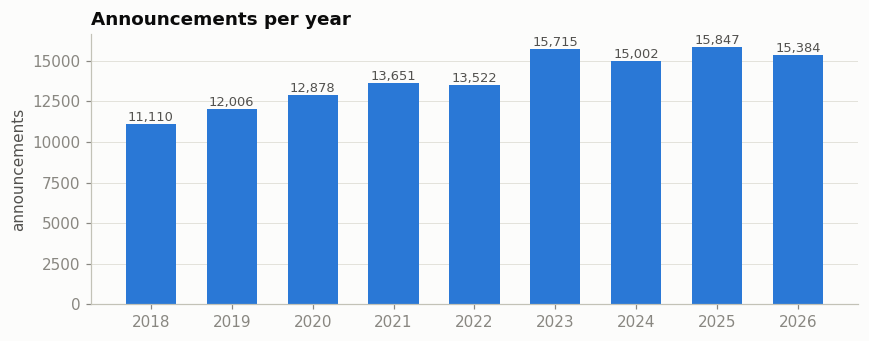

In [3]:
yearly = df.groupby("year").size()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(yearly.index.astype(str), yearly.values, color=BLUE, width=0.62, zorder=2)
for x, v in zip(yearly.index.astype(str), yearly.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.set_title("Announcements per year")
ax.set_ylabel("announcements"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 2. Announcements per company (activity distribution)

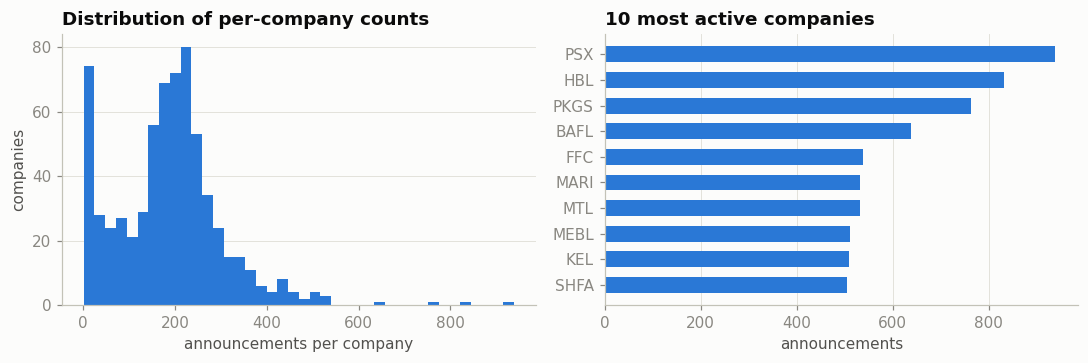

count    667.0
mean     187.6
std      119.2
min        1.0
25%      106.5
50%      190.0
75%      244.0
max      939.0
dtype: float64


In [4]:
per_co = df.groupby("symbol").size().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(per_co.values, bins=40, color=BLUE, zorder=2)
axes[0].set_title("Distribution of per-company counts")
axes[0].set_xlabel("announcements per company"); axes[0].set_ylabel("companies")
axes[0].grid(axis="x", visible=False)
top = per_co.tail(10)
axes[1].barh(top.index, top.values, color=BLUE, height=0.62, zorder=2)
axes[1].set_title("10 most active companies")
axes[1].set_xlabel("announcements"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(per_co.describe().round(1))

## 3. Event-type coverage (keyword tagger)
Magnitude comparison of one measure -> single hue.

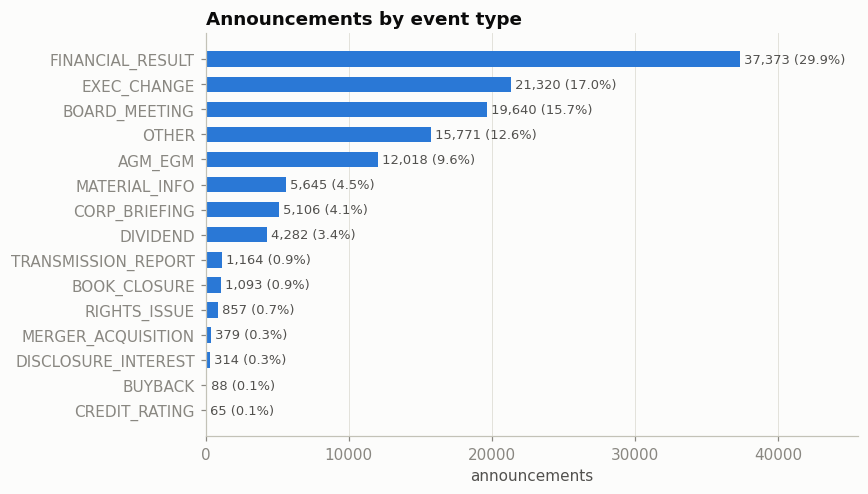

In [5]:
ev = df["event"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(ev.index[::-1], ev.values[::-1], color=BLUE, height=0.62, zorder=2)
for y, v in zip(ev.index[::-1], ev.values[::-1]):
    ax.text(v, y, f" {v:,} ({100*v/len(df):.1f}%)", va="center", fontsize=8.5, color=INK2)
ax.set_title("Announcements by event type")
ax.set_xlabel("announcements"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, ev.max() * 1.22)
plt.tight_layout(); plt.show()

## 4. Event mix over time
Top 6 event types as share of each year. Categorical colors, fixed assignment.

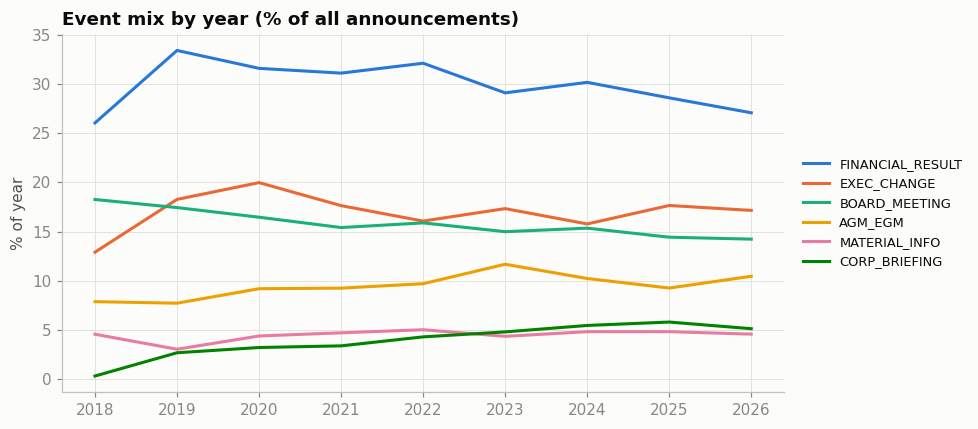

In [6]:
top_events = [e for e in df["event"].value_counts().index if e != "OTHER"][:6]
mix = (df[df["event"].isin(top_events)]
       .pivot_table(index="year", columns="event", aggfunc="size", fill_value=0))
share = 100 * mix.div(df.groupby("year").size(), axis=0)
fig, ax = plt.subplots(figsize=(9, 4))
for i, evt in enumerate(top_events):
    ax.plot(share.index, share[evt], color=CAT[i], linewidth=2, zorder=2, label=evt)
ax.set_title("Event mix by year (% of all announcements)")
ax.set_ylabel("% of year"); ax.set_xticks(share.index)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8.5, frameon=False)
plt.tight_layout(); plt.show()

## 5. Seasonality: announcements by month
Quarterly reporting rhythm. Sequential ramp (magnitude).

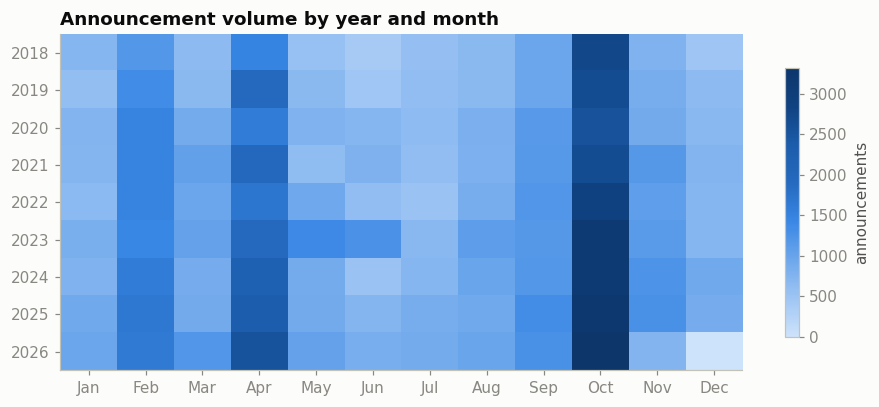

In [7]:
hm = df.pivot_table(index="year", columns=df["dt"].dt.month, aggfunc="size", fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(hm.values, aspect="auto", cmap=SEQ_CMAP)
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(hm.index)), hm.index)
ax.set_title("Announcement volume by year and month"); ax.grid(visible=False)
fig.colorbar(im, ax=ax, shrink=0.8, label="announcements")
plt.tight_layout(); plt.show()

## 6. Temporal texture for forecasting

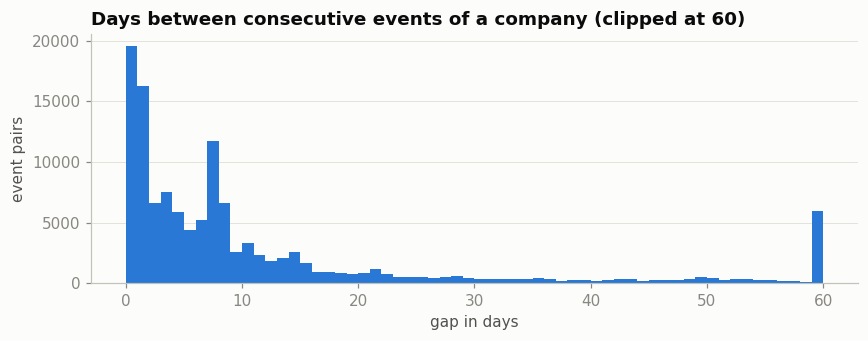

median gap: 6 d | p75: 12 d | p95: 56 d
mean events per company-month: 3.46


In [8]:
gaps = df.sort_values("dt").groupby("symbol")["dt"].diff().dt.days.dropna()
gaps_c = gaps.clip(upper=60)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(gaps_c, bins=60, color=BLUE, zorder=2)
ax.set_title("Days between consecutive events of a company (clipped at 60)")
ax.set_xlabel("gap in days"); ax.set_ylabel("event pairs"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"median gap: {gaps.median():.0f} d | p75: {gaps.quantile(.75):.0f} d | p95: {gaps.quantile(.95):.0f} d")
print("mean events per company-month:",
      round(df.groupby(["symbol", df.dt.dt.to_period("M")]).size().mean(), 2))

## 7. Data quality

In [9]:
print("exact (symbol,date,title) duplicates:", df.duplicated(["symbol","date","title"]).sum())
print("missing pdf_url:", df.pdf_url.isna().sum(), f"({100*df.pdf_url.isna().mean():.1f}%) - image-only announcements")
print("'View PDF' junk titles (parser artifact):", (df.title.str.strip() == "View PDF").sum())
print("\nTop 12 unmatched (OTHER) titles - schema gaps:")
print(df[df.event=="OTHER"].title.str.strip().value_counts().head(12).to_string())

exact (symbol,date,title) duplicates: 1373
missing pdf_url: 14199 (11.3%) - image-only announcements
'View PDF' junk titles (parser artifact): 101

Top 12 unmatched (OTHER) titles - schema gaps:
title
Miscellaneous Information                                           516
Change of Chief Financial Officer                                   119
View PDF                                                            101
Meeting in Progress                                                 100
Notice of Annual Review Meeting                                      99
Progress Report                                                      96
Rebalancing of JS Momentum Factor Exchange Traded Fund (JSMFETF)     79
Change of Registered Office                                          75
Credit/Dispatch of Bonus Share Certificates                          72
Credit of Bonus Share Certificates                                   68
Information under Clause 5.6.1(d) of PSX Regulations                 62
MEETING